# EDA D — Intent sequences and geography

**Zhaoyang Dong · DSAN 6000**

These three figures describe the simulated Banking77 chatbot stream. D1 asks what intent category comes next within a session. D2 compares distance from a user's home city. D3 shows which intents appear together in a flagged session.

The stream's `is_fraud` and `fraud_pattern` columns are **simulation ground truth**, used here only to compare groups. They are not available as real-time detection features. All source Parquet files are read-only; figures are written to `figures/zhaoyang/`.

## 0. Load and check the data

The notebook works when opened from either the repository root or this folder. It reads the 500,000-message dev stream, user home cities, cleaned Banking77 sentences, and the intent taxonomy. Since most stream labels are null, it recovers intent from message text. First, it checks that no text maps to two different intents and that recovered intents agree with the labels that *are* present.

In [17]:
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
import os
import textwrap

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "config" / "simulation.yaml").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the DSAN6000-Project repository")
FIG_DIR = ROOT / "figures" / "zhaoyang"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MSG_DIR = ROOT / "data" / "simulated" / "messages"
for path in (MSG_DIR, ROOT / "data" / "simulated" / "users.parquet",
             ROOT / "data" / "processed" / "banking77_clean.parquet",
             ROOT / "data" / "processed" / "dim_intent.parquet"):
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run the data preparation and dev simulation first.")

# Kaleido uses an installed browser to export the interactive Plotly Sankey as PNG.
for browser in (Path("C:/Program Files/Google/Chrome/Application/chrome.exe"),
                Path("C:/Program Files (x86)/Microsoft/Edge/Application/msedge.exe")):
    if browser.exists():
        os.environ.setdefault("BROWSER_PATH", str(browser))
        break
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Repository:", ROOT)

Repository: c:\Users\ROG\Desktop\GU6000\DSAN6000-Project


In [18]:
clean = pd.read_parquet(ROOT / "data" / "processed" / "banking77_clean.parquet")
dim = pd.read_parquet(ROOT / "data" / "processed" / "dim_intent.parquet")
users = pd.read_parquet(ROOT / "data" / "simulated" / "users.parquet")
msgs = pd.read_parquet(MSG_DIR, columns=["message_id", "received_ts", "text", "label",
                                         "user_id", "session_id", "lat", "lon",
                                         "is_fraud", "fraud_pattern"])

ambiguous = clean.groupby("text")["intent"].nunique()
if (ambiguous > 1).any():
    raise ValueError(f"{(ambiguous > 1).sum()} texts map to multiple intents")
text_to_intent = clean.drop_duplicates("text").set_index("text")["intent"]
msgs["intent"] = msgs["text"].map(text_to_intent)
if msgs["intent"].isna().any():
    raise ValueError(f"{msgs['intent'].isna().sum()} stream messages have no source intent")
intent_to_id = dim.set_index("intent")["intent_id"]
known = msgs["label"].notna()
if not (msgs.loc[known, "intent"].map(intent_to_id).to_numpy() ==
        msgs.loc[known, "label"].to_numpy()).all():
    raise ValueError("Recovered intents disagree with non-null stream labels")

meta = dim.set_index("intent")[["journey_stage", "fraud_type", "risk_level"]]
msgs["journey_stage"] = msgs["intent"].map(meta["journey_stage"])
msgs["received_ts"] = pd.to_datetime(msgs["received_ts"])
print(f"{len(msgs):,} messages, {msgs['session_id'].nunique():,} sessions, "
      f"{known.mean():.1%} labeled; text lookup validated")

500,000 messages, 147,102 sessions, 30.0% labeled; text lookup validated


## D1. Intent sequence Sankey diagram

Each band is a transition between **adjacent messages in one session**. The left side is the current topic; the right side is the next topic. Topics use `journey_stage`, except `receiving_money` is shown separately so the money-mule receive-then-send sequence remains visible. Band width is the number of transitions. Six panels show ordinary sessions and each of the five flagged patterns. Band widths are comparable **within** a panel, not across panels: each panel has its own total.

In [19]:
ordered = msgs.sort_values(["user_id", "session_id", "received_ts", "message_id"])
ordered["sequence_topic"] = np.where(ordered["intent"].eq("receiving_money"),
                                     "money_received", ordered["journey_stage"])
session = ordered.groupby("session_id", sort=False)
transitions = ordered[["session_id", "is_fraud", "fraud_pattern", "sequence_topic", "intent"]].copy()
transitions = transitions.rename(columns={"sequence_topic": "journey_stage"})
transitions["next_stage"] = session["sequence_topic"].shift(-1)
transitions["next_intent"] = session["intent"].shift(-1)
transitions = transitions.dropna(subset=["next_stage"])
transitions["group"] = np.where(transitions["is_fraud"],
                                transitions["fraud_pattern"], "ordinary")
transition_counts = (transitions.groupby(["group", "journey_stage", "next_stage"],
                                          observed=True).size().rename("n").reset_index())
GROUPS = ("ordinary", "account_takeover", "money_mule", "card_testing",
          "location_anomaly", "night_activity")
for group in GROUPS:
    sub = transition_counts[transition_counts.group == group].nlargest(8, "n")
    print(f"\n{group}: top stage transitions")
    print(sub[["journey_stage", "next_stage", "n"]].to_string(index=False))


ordinary: top stage transitions
   journey_stage       next_stage     n
  account_access   account_access 41510
        identity         identity 36021
        payments         payments 35944
       transfers        transfers 35934
      card_usage       card_usage 34119
      card_setup       card_setup 33004
            cash             cash 32626
foreign_exchange foreign_exchange 31827

account_takeover: top stage transitions
 journey_stage     next_stage   n
account_access account_access 430
     transfers      transfers 416
account_access      transfers 215

money_mule: top stage transitions
 journey_stage     next_stage   n
money_received money_received 521
     transfers      transfers 499
money_received      transfers 147

card_testing: top stage transitions
journey_stage next_stage   n
     payments   payments 919
       top_up   payments 188
   card_usage   payments 185
     payments     top_up 185
     payments card_usage 178
       top_up     top_up  40
   card_usage     t

In [20]:
STAGE_COLORS = {
    "account_access": "#c0392b", "transfers": "#2c6e9b", "payments": "#e67e22",
    "card_setup": "#8e6bbf", "card_usage": "#4a90c2", "cash": "#16a085",
    "top_up": "#27ae60", "identity": "#d35400", "refunds": "#a66a44",
    "foreign_exchange": "#7f8c8d", "limits": "#64748b", "money_received": "#6f42c1",
}
def stage_label(s):
    return s.replace("_", " ").title()

session_counts = ordered.groupby("session_id").first().assign(
    group=lambda f: np.where(f["is_fraud"], f["fraud_pattern"], "ordinary"))[
        "group"].value_counts().to_dict()
titles = [f"{group.replace('_', ' ').title()} ({session_counts[group]:,} sessions)"
          for group in GROUPS]
fig = make_subplots(rows=3, cols=2,
    specs=[[{"type": "sankey"}, {"type": "sankey"}] for _ in range(3)],
    subplot_titles=titles, horizontal_spacing=0.12, vertical_spacing=0.08)
for panel, group in enumerate(GROUPS):
    row, col = divmod(panel, 2)
    links = transition_counts[transition_counts.group == group].copy()
    # Ordinary sessions are numerous; retain their 15 most common stage transitions.
    if group == "ordinary":
        links = links.nlargest(15, "n")
    stages = sorted(set(links.journey_stage) | set(links.next_stage))
    idx = {stage: i for i, stage in enumerate(stages)}
    n_stages = len(stages)
    colors = [STAGE_COLORS.get(stage, "#7f8c8d") for stage in stages]
    link_colors = [f"rgba({int(colors[idx[s]][1:3], 16)},"
                   f"{int(colors[idx[s]][3:5], 16)},"
                   f"{int(colors[idx[s]][5:7], 16)},0.38)"
                   for s in links.journey_stage]
    fig.add_trace(go.Sankey(
        arrangement="snap",
        node=dict(label=[stage_label(s) for s in stages] * 2,
                  color=colors * 2, pad=13, thickness=13),
        link=dict(source=[idx[s] for s in links.journey_stage],
                  target=[n_stages + idx[s] for s in links.next_stage],
                  value=links.n.tolist(),
                  color=link_colors,
                  customdata=[f"{stage_label(a)} → {stage_label(b)}" for a, b in
                              zip(links.journey_stage, links.next_stage)],
                  hovertemplate="%{customdata}<br>%{value:,} transitions<extra></extra>"),
        valueformat=",d"), row=row + 1, col=col + 1)
fig.update_layout(title="D1 · What comes next in a chatbot session?",
                  font=dict(size=10), width=2100, height=1800,
                  margin=dict(l=20, r=20, t=100, b=35))
fig.show()
fig.write_image(FIG_DIR / "D1_intent_sequence_sankey.png", scale=1.5)
print("Saved", FIG_DIR / "D1_intent_sequence_sankey.png")

Saved c:\Users\ROG\Desktop\GU6000\DSAN6000-Project\figures\zhaoyang\D1_intent_sequence_sankey.png


**Banking interpretation.** Ordinary sessions stay within one service topic, while all 215 simulated account takeover sessions cross from account-access questions into transfers. Money mule shows receiving-money questions followed by other transfer questions, and card testing mixes payment, card-usage, and limit topics; location and night patterns are primarily about geography or time, so their defining signals are outside this chart. These patterns are generator-defined, so the figure illustrates possible review features rather than their accuracy on real fraud.

## D2. Distance from the user's home city

The first panel shows the share of messages sent away from home for **ordinary messages and all five simulated fraud patterns**. The second compares the **distance among away messages only**; patterns with zero away messages have no distance distribution to draw. Distances use the haversine formula and the coordinates in the messages and users tables. The unit here is a message; repeated messages in one visit therefore count more than a short visit.

In [21]:
geo = msgs[["message_id", "user_id", "session_id", "lat", "lon",
            "is_fraud", "fraud_pattern"]].merge(
                users[["user_id", "home_lat", "home_lon"]], on="user_id", validate="many_to_one")
lat1, lon1 = np.radians(geo["home_lat"].to_numpy()), np.radians(geo["home_lon"].to_numpy())
lat2, lon2 = np.radians(geo["lat"].to_numpy()), np.radians(geo["lon"].to_numpy())
a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
geo["distance_km"] = 6371.0 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
geo["group"] = np.where(geo["is_fraud"], geo["fraud_pattern"], "ordinary")
geo["away"] = geo.distance_km > 1
geo_summary = geo.groupby("group").agg(
    messages=("message_id", "size"), away_messages=("away", "sum"),
    away_share=("away", "mean"))
print(geo_summary.to_string(float_format=lambda x: f"{x:.3f}"))
print("Away-distance medians (km):", geo[geo.away].groupby("group").distance_km.median().round(0).to_dict())

                  messages  away_messages  away_share
group                                                
account_takeover      1276              0       0.000
card_testing          1976              0       0.000
location_anomaly       772            772       1.000
money_mule            1314              0       0.000
night_activity        1079              0       0.000
ordinary            493583          15034       0.030
Away-distance medians (km): {'location_anomaly': 2058.0, 'ordinary': 2088.0}


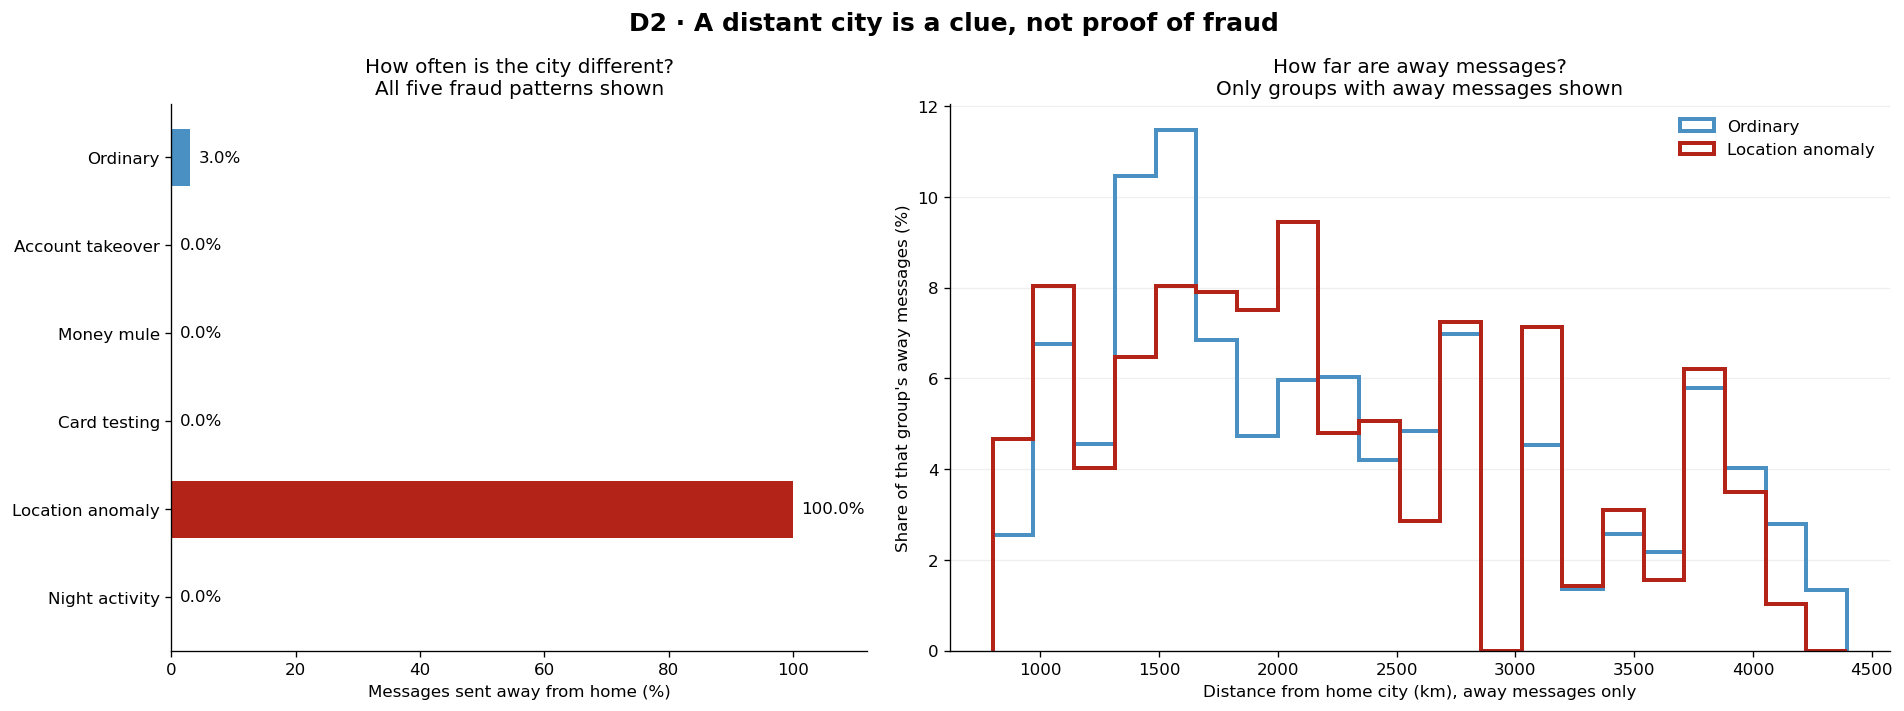

Saved c:\Users\ROG\Desktop\GU6000\DSAN6000-Project\figures\zhaoyang\D2_distance_from_home.png


In [22]:
geo_groups = ["ordinary", "account_takeover", "money_mule", "card_testing",
              "location_anomaly", "night_activity"]
colors = {"ordinary": "#4a90c2", "account_takeover": "#c0392b",
          "money_mule": "#8e6bbf", "card_testing": "#e67e22",
          "location_anomaly": "#b42318", "night_activity": "#16a085"}
labels = {"ordinary": "Ordinary", "account_takeover": "Account takeover",
          "money_mule": "Money mule", "card_testing": "Card testing",
          "location_anomaly": "Location anomaly", "night_activity": "Night activity"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6.0), gridspec_kw={"width_ratios": [1.0, 1.35]})
shares = [geo_summary.loc[g, "away_share"] * 100 for g in geo_groups]
y = np.arange(len(geo_groups))
bars = axes[0].barh(y, shares, color=[colors[g] for g in geo_groups], height=0.65)
axes[0].set_yticks(y, [labels[g] for g in geo_groups])
axes[0].invert_yaxis()
axes[0].bar_label(bars, labels=[f"{x:.1f}%" for x in shares], padding=5)
axes[0].set_xlabel("Messages sent away from home (%)")
axes[0].set_xlim(0, 112)
axes[0].set_title("How often is the city different?\nAll five fraud patterns shown")

away_groups = [g for g in geo_groups if geo_summary.loc[g, "away_messages"] > 0]
bins = np.linspace(800, max(geo.distance_km.max(), 1000), 22)
for group in away_groups:
    away = geo.loc[(geo.group == group) & geo.away, "distance_km"]
    axes[1].hist(away, bins=bins, weights=np.ones(len(away)) / len(away) * 100,
                 histtype="step", linewidth=2.4, color=colors[group], label=labels[group])
axes[1].set_xlabel("Distance from home city (km), away messages only")
axes[1].set_ylabel("Share of that group's away messages (%)")
axes[1].set_title("How far are away messages?\nOnly groups with away messages shown")
axes[1].legend(frameon=False)
axes[1].grid(axis="y", alpha=0.2)
fig.suptitle("D2 · A distant city is a clue, not proof of fraud", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "D2_distance_from_home.png", bbox_inches="tight")
plt.show()
print("Saved", FIG_DIR / "D2_distance_from_home.png")

**Banking interpretation.** Every `location_anomaly` burst occurs away from home by construction, while the other four simulated fraud patterns stay at home; 3.0% of ordinary messages are away too. Among away messages, the ordinary and location-anomaly distance medians are similar (2,088 km and 2,058 km), so a bank would need recent location history and other context before escalating a distant session. These are simulated city centers, not precise device locations or verified impossible travel.

## D3. Intent co-occurrence network

A node is one Banking77 intent. Two nodes connect when both appeared in the **same flagged session**, regardless of order. Each pair is counted once per session, even if an intent repeats. To avoid a dense hairball, the graph shows the six most frequent pairs from each simulated fraud pattern. Node color comes from the *intent taxonomy*, which is different from the session's fraud pattern; gray means that the intent itself has no fraud type.

In [23]:
fraud_sessions = msgs.loc[msgs.is_fraud, ["session_id", "fraud_pattern", "intent"]]
pair_counts = defaultdict(Counter)
for (session_id, pattern), frame in fraud_sessions.groupby(["session_id", "fraud_pattern"], sort=False):
    unique_intents = sorted(set(frame.intent))
    pair_counts[pattern].update(combinations(unique_intents, 2))
selected_edges = {}
for pattern, counts in pair_counts.items():
    for edge, count in counts.most_common(6):
        selected_edges.setdefault(edge, {})[pattern] = count
G = nx.Graph()
for (a, b), counts in selected_edges.items():
    G.add_edge(a, b, weight=sum(counts.values()), pattern=max(counts, key=counts.get))
print(f"Network: {G.number_of_nodes()} intents, {G.number_of_edges()} high-frequency pairs")
for pattern, counts in pair_counts.items():
    print(f"{pattern}: {counts.most_common(2)}")

Network: 17 intents, 26 high-frequency pairs
night_activity: [(('declined_transfer', 'transfer_timing'), 91), (('balance_not_updated_after_bank_transfer', 'declined_transfer'), 87)]
account_takeover: [(('edit_personal_details', 'passcode_forgotten'), 139), (('change_pin', 'edit_personal_details'), 132)]
money_mule: [(('beneficiary_not_allowed', 'receiving_money'), 76), (('receiving_money', 'transfer_not_received_by_recipient'), 68)]
card_testing: [(('declined_card_payment', 'disposable_card_limits'), 145), (('declined_card_payment', 'top_up_limits'), 143)]
location_anomaly: [(('declined_card_payment', 'pending_card_payment'), 69), (('card_payment_not_recognised', 'cash_withdrawal_not_recognised'), 67)]


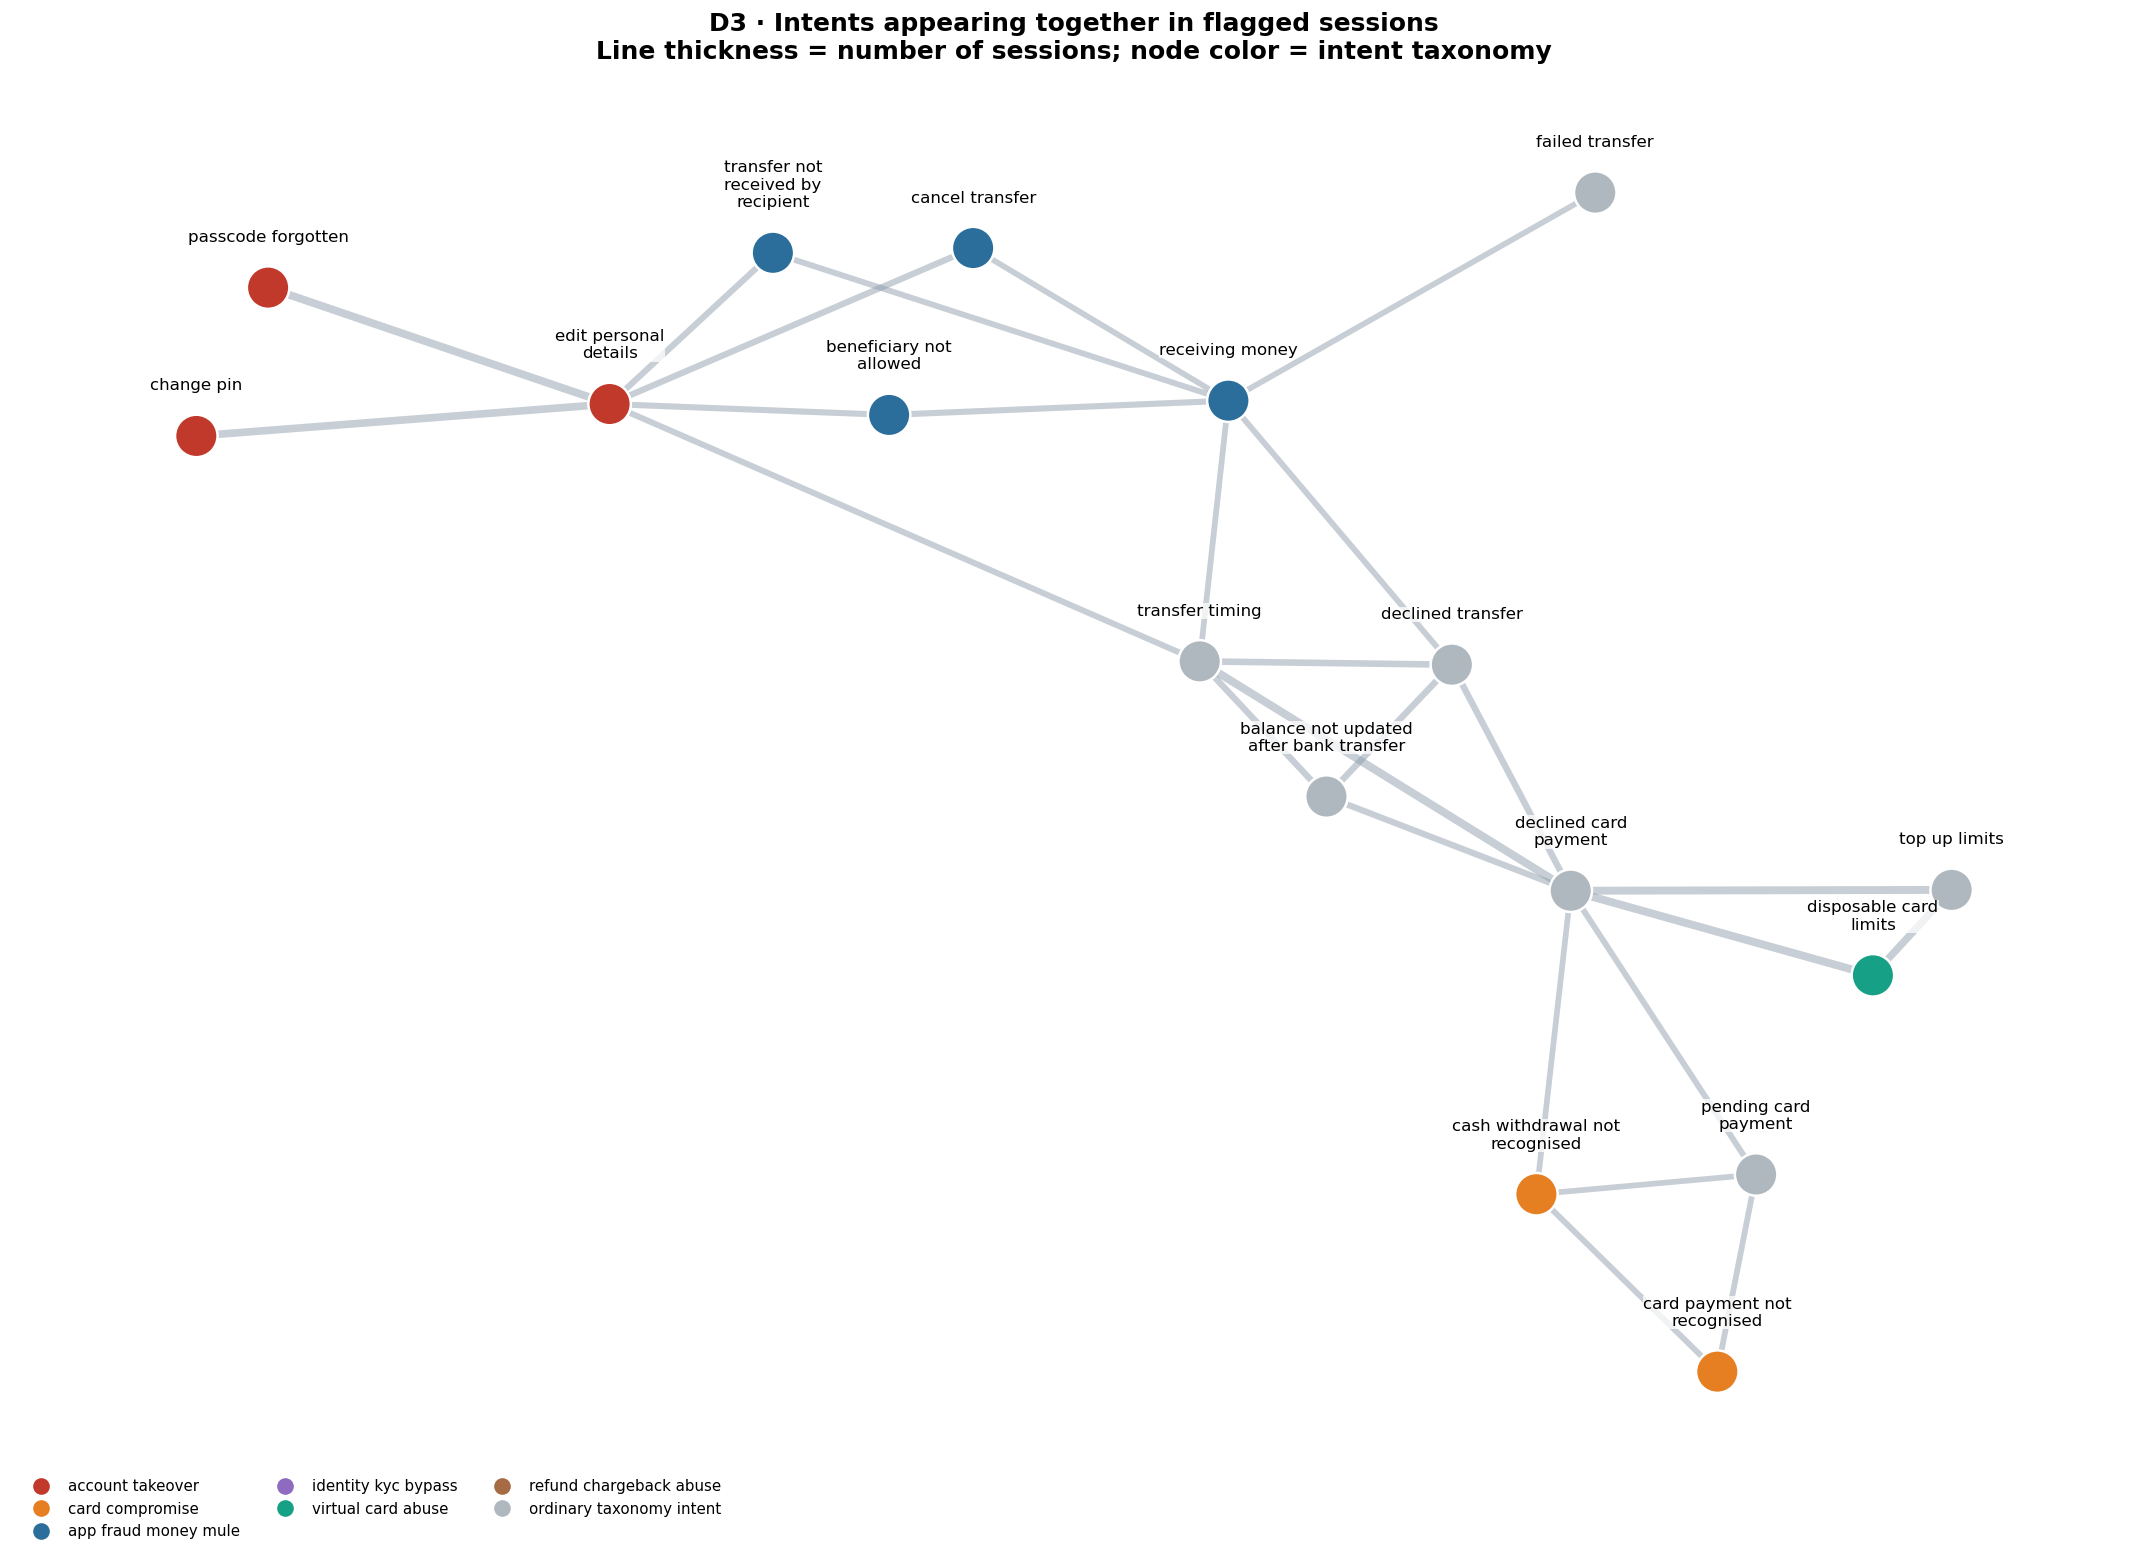

Saved c:\Users\ROG\Desktop\GU6000\DSAN6000-Project\figures\zhaoyang\D3_intent_cooccurrence_network.png


In [24]:
TYPE_COLORS = {
    "account_takeover": "#c0392b", "card_compromise": "#e67e22",
    "app_fraud_money_mule": "#2c6e9b", "identity_kyc_bypass": "#8e6bbf",
    "virtual_card_abuse": "#16a085", "refund_chargeback_abuse": "#a66a44",
}
intent_type = meta["fraud_type"].to_dict()
node_colors = [TYPE_COLORS.get(intent_type[node], "#b0b8bf") for node in G.nodes]
weights = np.array([G[u][v]["weight"] for u, v in G.edges], dtype=float)
edge_width = 0.8 + 4 * np.sqrt(weights / weights.max())
pos = nx.spring_layout(G, seed=7, iterations=400, weight="weight", k=0.8)
fig, ax = plt.subplots(figsize=(18, 13))
nx.draw_networkx_edges(G, pos, ax=ax, width=edge_width, edge_color="#8a9aa8", alpha=0.48)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=650,
                       edgecolors="white", linewidths=1.5)
short_names = {node: "\n".join(textwrap.wrap(node.replace("_", " "), width=19))
               for node in G.nodes}
label_pos = {node: (x, y + 0.06) for node, (x, y) in pos.items()}
nx.draw_networkx_labels(G, label_pos, labels=short_names, ax=ax, font_size=10,
                        font_weight="normal", verticalalignment="bottom",
                        bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=0.2))
legend = [Line2D([0], [0], marker="o", color="w", markerfacecolor=color,
                 markersize=11, label=name.replace("_", " "))
          for name, color in TYPE_COLORS.items()]
legend.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="#b0b8bf",
                     markersize=11, label="ordinary taxonomy intent"))
ax.legend(handles=legend, loc="lower left", bbox_to_anchor=(0.0, -0.04),
          ncol=3, frameon=False, fontsize=9)
ax.set_title("D3 · Intents appearing together in flagged sessions\n"
             "Line thickness = number of sessions; node color = intent taxonomy",
             fontsize=15, fontweight="bold")
ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "D3_intent_cooccurrence_network.png", bbox_inches="tight")
plt.show()
print("Saved", FIG_DIR / "D3_intent_cooccurrence_network.png")

**Banking interpretation.** Strong links identify topics a customer raises together during a simulated fraud burst; gray nodes remind us that ordinary-sounding transfer or payment questions can still participate in a flagged sequence. Co-occurrence does **not** show which intent came first—use D1 for that—and the network's selected edges are descriptive, not a validated detector.

## Scope and reproducibility

- Inputs: `data/processed/banking77_clean.parquet`, `data/processed/dim_intent.parquet`, `data/simulated/messages/`, and `data/simulated/users.parquet`.
- Outputs: three PNG files in `figures/zhaoyang/`.
- Python packages: pandas, pyarrow, NumPy, Matplotlib, Plotly, Kaleido, and NetworkX. Plotly PNG export also needs a local Chrome or Edge installation.
- The dev stream is generated with seed 7 and contains simulated behavior. Session order, cities, and fraud flags are not observations from a bank.